# DSA4212 Group 10 - Training Small Language Models under a Fixed Compute Budget

**Research question:** Under a fixed GPU training-time budget, can a smaller Transformer trained on more tokens outperform a larger one trained on fewer tokens?


**Completed work:** 17 learning-rate tuning runs, 5 tokenizer runs, 5 model-size runs, 3 batch-size runs, and 6 seed runs (**36 training runs**); plus **16 held-out test evaluations** (5 tokenizer, 5 size, 6 seeds).


**Headline finding:** For the five model sizes trained for 1,800 seconds on a T4 using BPE 16K, **M** achieved the lowest validation BPB (1.1261) and test BPB (1.1461). BPE 16K was selected on validation BPB. See `results/headline_size_table.csv` and `results/final_test_comparison.csv` for source data.



## 1. GPU and environment

In [ ]:
import sys, json, os, time, shutil, subprocess, re, platform
from pathlib import Path
import torch
print('Python:', sys.version.split()[0]); print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
assert torch.cuda.is_available(), 'Select a GPU runtime in Runtime > Change runtime type.'
GPU_NAME = torch.cuda.get_device_name(0)
print('GPU:', GPU_NAME)
print('VRAM GB:', round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))
print('CUDA:', torch.version.cuda)

Python: 3.13.16
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
VRAM GB: 15.64
CUDA: 13.0


## 2. Mount Drive and connect the repository
The four parquet files already live in `MyDrive/DSA4212/Dataset`.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
REPO = Path('/content/DSA4212_Group_10_Assignment')
DATA_DIR = Path('/content/drive/MyDrive/DSA4212/Dataset')
DRIVE_OUTPUT = Path('/content/drive/MyDrive/DSA4212/week1_smoke')

DRIVE_OUTPUT.mkdir(parents=True, exist_ok=True)
assert DATA_DIR.is_dir(), f'Cannot find dataset: {DATA_DIR}'
if not (REPO / '.git').exists():
    subprocess.run(['git','clone','https://github.com/Alutare/DSA4212_Group_10_Assignment.git',str(REPO)],check=True)
print('Repo:', REPO)
print('Repo commit:', subprocess.check_output(['git','-C',str(REPO),'rev-parse','HEAD'],text=True).strip())

Mounted at /content/drive
Repo: /content/DSA4212_Group_10_Assignment
Repo commit: bc9cd790849c32eb9a1d75dfaf3747254c619995


## 3. Install required packages

In [ ]:
subprocess.run([sys.executable,'-m','pip','install','-q','-r',str(REPO/'requirements-data.txt')],check=True)
subprocess.run([sys.executable,'-m','pip','install','-q','tiktoken'],check=True)
import tiktoken, numpy as np, pyarrow.parquet as pq
print('tiktoken:', tiktoken.__version__ if hasattr(tiktoken,'__version__') else 'installed')

tiktoken: 0.14.0


## 4. Verify dataset loader
Make a symlink without copying the dataset.

In [ ]:
LINK = REPO.parent / 'wikitext-103-raw-v1'
if LINK.is_symlink():
    assert LINK.resolve() == DATA_DIR.resolve(), f'Existing symlink points elsewhere: {LINK.resolve()}'
elif LINK.exists():
    assert LINK.resolve() == DATA_DIR.resolve(), f'Unexpected existing directory: {LINK}'
else:
    LINK.symlink_to(DATA_DIR, target_is_directory=True)
FILES = {'train':['train-00000-of-00002.parquet','train-00001-of-00002.parquet'],
         'val':['validation-00000-of-00001.parquet'],
         'test':['test-00000-of-00001.parquet']}
for split, names in FILES.items():
    for name in names:
        assert (DATA_DIR/name).is_file(), f'Missing {name}'
print('All four parquet files found.')
subprocess.run([sys.executable,str(REPO/'code/check_data.py')],cwd=REPO,check=True)

All four parquet files found.


CompletedProcess(args=['/usr/bin/python3', '/content/DSA4212_Group_10_Assignment/code/check_data.py'], returncode=0)

## 5. Tokenize the dataset once
Use GPT-2 BPE **tokenizer only**; no pretrained neural weights. Tokenize each parquet row, appending a newline separator as a separate tokenization unit. The same procedure applies to all splits. The output is uint16 token IDs. **Keep the test split untouched until final evaluation.**

In [ ]:
ENC = tiktoken.get_encoding('gpt2')
assert ENC.n_vocab == 50257
print('GPT-2 vocabulary:', ENC.n_vocab, 'EOT:', ENC.eot_token)
PREPARED = REPO / 'data' / 'wikitext103'
PREPARED.mkdir(parents=True, exist_ok=True)
# One separator tokenization per row: independent of parquet batch boundaries.
NEWLINE_IDS = ENC.encode_ordinary('\n')
assert NEWLINE_IDS

def prepare_split(split, force=False):
    dest = PREPARED / f'{split}.bin'
    if dest.exists() and dest.stat().st_size > 0 and not force:
        print(split, 'cached:', dest.stat().st_size // 2, 'tokens')
        return
    temp = dest.with_suffix('.bin.partial')
    count = 0
    with open(temp,'wb') as out:
        for filename in FILES[split]:
            pf = pq.ParquetFile(DATA_DIR / filename)
            for batch in pf.iter_batches(batch_size=512,columns=['text']):
                texts = batch.column(0).to_pylist()
                ids = []
                for text in texts:
                    if text is None:
                        continue
                    ids.extend(ENC.encode_ordinary(text))
                    ids.extend(NEWLINE_IDS)
                np.asarray(ids,dtype=np.uint16).tofile(out)
                count += len(ids)
    temp.replace(dest)
    print(split, 'wrote:', count, 'tokens')

for split in ('train','val','test'):
    prepare_split(split)
for split in ('train','val','test'):
    a=np.memmap(PREPARED/f'{split}.bin',dtype=np.uint16,mode='r')
    assert len(a)>129 and int(a.max())<ENC.n_vocab
    print(split, 'tokens:',len(a),'first:',a[:8].tolist())

GPT-2 vocabulary: 50257 EOT: 50256
train wrote: 119721490 tokens
val wrote: 251049 tokens
test wrote: 287645 tokens
train tokens: 119721490 first: [198, 796, 569, 18354, 7496, 17740, 6711, 796]
val tokens: 251049 first: [198, 796, 8074, 20272, 9106, 3876, 385, 796]
test tokens: 287645 first: [198, 796, 5199, 347, 2852, 353, 796, 220]


## 6. Clone a pinned nanoGPT implementation
`init_from=scratch` ensures random weights.

In [ ]:
NANO = Path('/content/nanoGPT')
if not (NANO/'.git').exists():
    subprocess.run(['git','clone','https://github.com/karpathy/nanoGPT.git',str(NANO)],check=True)
PINNED_SHA='3adf61e154c3fe3fca428ad6bc3818b27a3b8291'   # commit used in Part 1 (reproducibility)
subprocess.run(['git','-C',str(NANO),'checkout','-q',PINNED_SHA],check=True)
NANO_SHA=subprocess.check_output(['git','-C',str(NANO),'rev-parse','HEAD'],text=True).strip()
print('nanoGPT commit:',NANO_SHA)
NANO_DATA=NANO/'data'/'wikitext103'
NANO_DATA.mkdir(parents=True,exist_ok=True)
for name in ('train.bin','val.bin'):
    src=PREPARED/name
    dst=NANO_DATA/name
    if not dst.exists() or dst.stat().st_size != src.stat().st_size:
        shutil.copy2(src,dst)
print('Training binaries ready:', [(p.name,p.stat().st_size) for p in NANO_DATA.glob('*.bin')])

nanoGPT commit: 3adf61e154c3fe3fca428ad6bc3818b27a3b8291
Training binaries ready: [('val.bin', 502098), ('train.bin', 239442980)]


## 7. Small GPT: 200-step smoke test


In [ ]:
OUT=NANO/'out-week1-smoke'
LOG=REPO/'week1_smoke_train.log'
CMD=[sys.executable,'train.py',
    '--dataset=wikitext103','--out_dir=out-week1-smoke',
    '--init_from=scratch','--n_layer=4','--n_head=4','--n_embd=128',
    '--block_size=128','--batch_size=16','--gradient_accumulation_steps=1',
    '--learning_rate=3e-4','--max_iters=200','--warmup_iters=20',
    '--lr_decay_iters=200','--min_lr=3e-5','--eval_interval=50',
    '--eval_iters=20','--log_interval=10','--dtype=float16',
    '--compile=False','--wandb_log=False','--device=cuda']
print('Command:', ' '.join(CMD))
print('Training; please wait...')
start=time.perf_counter()
with open(LOG,'w') as f:
    result=subprocess.run(CMD,cwd=NANO,stdout=f,stderr=subprocess.STDOUT)
wall_seconds=time.perf_counter()-start
print('Exit code:',result.returncode,'Wall time (s, includes validation and setup):',round(wall_seconds,1))
logtext=LOG.read_text(errors='replace')
print(logtext[-10000:])
if result.returncode:
    raise RuntimeError('Training failed; inspect the log tail above.')

Command: /usr/bin/python3 train.py --dataset=wikitext103 --out_dir=out-week1-smoke --init_from=scratch --n_layer=4 --n_head=4 --n_embd=128 --block_size=128 --batch_size=16 --gradient_accumulation_steps=1 --learning_rate=3e-4 --max_iters=200 --warmup_iters=20 --lr_decay_iters=200 --min_lr=3e-5 --eval_interval=50 --eval_iters=20 --log_interval=10 --dtype=float16 --compile=False --wandb_log=False --device=cuda
Training; please wait...
Exit code: 0 Wall time (s, includes validation and setup): 18.5
/content/nanoGPT/train.py:196: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(dtype == 'float16'))
Overriding: dataset = wikitext103
Overriding: out_dir = out-week1-smoke
Overriding: init_from = scratch
Overriding: n_layer = 4
Overriding: n_head = 4
Overriding: n_embd = 128
Overriding: block_size = 128
Overriding: batch_size = 16
Overriding: gradient_accumulation_steps = 

## 8. Check the validation curve and model size

Validation points: [(0, 10.8342), (50, 9.1225), (100, 7.9886), (150, 7.5889), (200, 7.4822)]


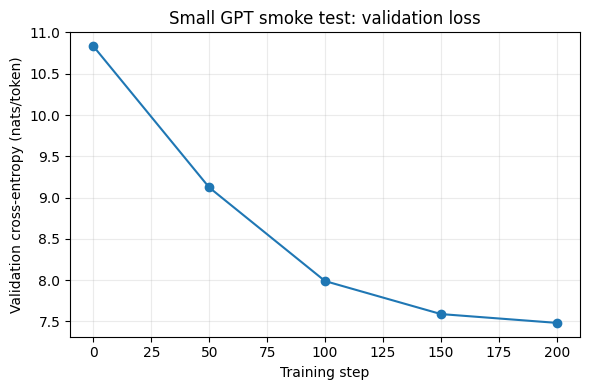

Start/end validation loss: 10.8342 7.4822
Improved: True


In [ ]:
import matplotlib.pyplot as plt
pairs=[(int(a),float(b)) for a,b in re.findall(r'step (\d+): train loss [0-9.]+, val loss ([0-9.]+)',logtext)]
print('Validation points:',pairs)
assert len(pairs)>=2, 'No validation curve found; inspect training log.'
xs,ys=zip(*pairs)
plt.figure(figsize=(6,4))
plt.plot(xs,ys,marker='o')
plt.xlabel('Training step');plt.ylabel('Validation cross-entropy (nats/token)')
plt.title('Small GPT smoke test: validation loss')
plt.grid(alpha=.25);plt.tight_layout()
FIG=REPO/'week1_smoke_validation.png'
plt.savefig(FIG,dpi=160)
plt.show()
print('Start/end validation loss:',ys[0],ys[-1])
print('Improved:',ys[-1]<ys[0])

In [ ]:
# Add nanoGPT to Python path
sys.path.insert(0, "/content/nanoGPT")

from model import GPT, GPTConfig

print("nanoGPT model imported successfully!")

# Correct checkpoint directory
OUT = Path("/content/nanoGPT/out-week1-smoke")
CKPT = OUT / "ckpt.pt"

assert CKPT.exists(), f"No checkpoint at {CKPT}"

# Load checkpoint
ckpt = torch.load(CKPT, map_location="cpu", weights_only=False)

# Reconstruct model
model = GPT(GPTConfig(**ckpt["model_args"]))
model.load_state_dict(ckpt["model"])

# Calculate parameters
params = sum(p.numel() for p in model.parameters())

print("Parameter count:", f"{params:,}")
print("Checkpoint step:", ckpt["iter_num"])
print("Best validation loss:", ckpt["best_val_loss"])
print("Training tokens per optimizer step:", 16 * 128)
print("Approximate tokens through 200 updates:", 200 * 16 * 128)

del model, ckpt

nanoGPT model imported successfully!
number of parameters: 7.23M
Parameter count: 7,242,880
Checkpoint step: 200
Best validation loss: tensor(7.4822)
Training tokens per optimizer step: 2048
Approximate tokens through 200 updates: 409600


## 9. Back up checkpoint, metrics, and training log

In [ ]:
import hashlib
repo_sha=subprocess.check_output(['git','-C',str(REPO),'rev-parse','HEAD'],text=True).strip()
metadata={
    'purpose':'week1_smoke_test_not_final',
    'gpu':GPU_NAME,'torch':torch.__version__,'python':platform.python_version(),
    'repo_commit':repo_sha,'nanogpt_commit':NANO_SHA,
    'dataset':'WikiText-103 raw parquet from MyDrive/DSA4212/Dataset',
    'tokenizer':'tiktoken GPT-2 BPE','vocab_size':ENC.n_vocab,
    'preprocessing':'each non-null parquet text row encoded separately followed by encoded newline',
    'model':{'n_layer':4,'n_head':4,'n_embd':128,'block_size':128,'params':params},
    'train':{'batch_size':16,'gradient_accumulation_steps':1,'learning_rate':3e-4,
             'max_iters_configured':200,'dtype':'float16','compile':False},
    'wall_seconds_including_eval_and_setup':round(wall_seconds,3),
    'validation_loss_by_step':dict(pairs),
    'checkpoint_iteration':int(torch.load(CKPT,map_location='cpu',weights_only=False)['iter_num']),
    'note':'nanoGPT original stopping logic may execute one extra update; not an exact-budget run.'
}
META=REPO/'week1_smoke_metrics.json'
META.write_text(json.dumps(metadata,indent=2))
for source in (CKPT,LOG,FIG,META):
    shutil.copy2(source,DRIVE_OUTPUT / ('small_smoke_ckpt.pt' if source==CKPT else source.name))
print('Backed up:', [p.name for p in DRIVE_OUTPUT.iterdir()])

Backed up: ['small_smoke_ckpt.pt', 'week1_smoke_metrics.json', 'week1_smoke_train.log', 'week1_smoke_validation.png']


---
# PART 2 - Fixed-budget experiments

Part 1 above documents the initial nanoGPT smoke test. Part 2 contains the original reproducible code for the fixed-budget studies.

The experiment runner supports 1,800 seconds of optimization-step training time per final run, checkpoint/resume, and bits-per-byte evaluation. Results and checkpoint files were saved to Google Drive, while lightweight metrics, plots and logs were exported to GitHub.


## 10. Part 2 setup (reuses `REPO`, `DATA_DIR`, `PREPARED` from Part 1)

In [ ]:
import os, sys, shutil, subprocess
from pathlib import Path

DRIVE   = '/content/drive/MyDrive/DSA4212'
PARQUET = str(DATA_DIR)                  # same Drive folder Part 1 used
RUNS    = f'{DRIVE}/runs'                # all run results live on Drive
TOKS    = f'{DRIVE}/tokenizers'
DATA    = '/content/data'                # fast local copy of the new .bin files
for d in (RUNS, TOKS, DATA): Path(d).mkdir(parents=True, exist_ok=True)

subprocess.run(['git', '-C', str(REPO), 'pull'], check=False)      # pick up the pushed code/ folder
CODE = f'{REPO}/code'
assert Path(f'{CODE}/train.py').exists(), "code/train.py not found: push the new code/ folder to GitHub first"
os.chdir(CODE); sys.path.insert(0, CODE)
print('Using code from', CODE)

Using code from /content/DSA4212_Group_10_Assignment/code


In [ ]:
!pip install -q tiktoken tokenizers pyarrow pandas matplotlib && python test_utils.py

plan ok n=1000 T=64 stride=64: 16 windows
plan ok n=1001 T=64 stride=64: 16 windows
plan ok n=1000 T=64 stride=16: 60 windows
plan ok n=999 T=64 stride=32: 31 windows
plan ok n=65 T=64 stride=64: 1 windows
plan ok n=66 T=64 stride=10: 2 windows
plan ok n=5000 T=128 stride=128: 40 windows
plan ok n=5000 T=128 stride=32: 154 windows
ALL TESTS PASSED


## 11. Declared compute budget

In [ ]:
import experiments as E
print("Hardware      :", E.HARDWARE)
print("Budget / run  :", E.BUDGET_SECONDS, "s of optimisation-step wall-clock (eval + checkpoint time excluded; compile time included)")
print("Tuning runs   :", round(E.BUDGET_SECONDS*E.TUNE_FRACTION), "s each (preliminary, excluded from the budget)")
print("Init          : random (no pretrained weights/embeddings); tokenizers trained on WikiText train only or GPT-2 BPE merges (no neural components)")
print("Metric        : validation/test bits-per-byte (tokeniser-independent) + perplexity")

Hardware      : 1x NVIDIA Tesla T4 (16 GB), Google Colab, fp16 mixed precision
Budget / run  : 1800 s of optimisation-step wall-clock (eval + checkpoint time excluded; compile time included)
Tuning runs   : 300 s each (preliminary, excluded from the budget)
Init          : random (no pretrained weights/embeddings); tokenizers trained on WikiText train only or GPT-2 BPE merges (no neural components)
Metric        : validation/test bits-per-byte (tokeniser-independent) + perplexity


## 12. GPT-2 BPE data (cached on Drive after the first time)

In [ ]:
import shutil
def ensure_data(name, tokenizer):
    local, cached = Path(DATA)/name, Path(DRIVE)/'data'/name
    if (local/'meta.json').exists(): return print(name, 'ready (local)')
    if (cached/'meta.json').exists():
        shutil.copytree(cached, local); return print(name, 'copied from Drive')
    !python prepare_data.py --data_dir {PARQUET} --tokenizer {tokenizer} --name {name} --out_root {DATA}
    shutil.copytree(local, cached, dirs_exist_ok=True)
ensure_data('gpt2', 'gpt2')

gpt2 copied from Drive


**Continuity check with Part 1:** the new `gpt2` tokenisation must contain exactly the same tokens as the Part 1 files.

In [ ]:
import numpy as np, json
meta = json.load(open(f'{DATA}/gpt2/meta.json'))
for split in ('train', 'val', 'test'):
    old = np.memmap(PREPARED/f'{split}.bin', dtype=np.uint16, mode='r')
    new_ = np.memmap(f'{DATA}/gpt2/{split}.bin', dtype=np.uint16, mode='r')
    assert len(old) == len(new_), (split, len(old), len(new_))
    assert (old[:100000] == new_[:100000]).all()
    print(f"{split}: {len(new_):,} tokens identical to Part 1 | {meta['bytes'][split]:,} bytes | "
          f"{meta['bytes'][split]/len(new_):.3f} bytes/token | round-trip mismatches {meta['roundtrip_mismatches'][split]}")

train: 119,721,490 tokens identical to Part 1 | 541,096,899 bytes | 4.520 bytes/token | round-trip mismatches 0/5000
val: 251,049 tokens identical to Part 1 | 1,148,008 bytes | 4.573 bytes/token | round-trip mismatches 0/1000
test: 287,645 tokens identical to Part 1 | 1,292,014 bytes | 4.492 bytes/token | round-trip mismatches 0/1262


## 13. Custom tokenizers (trained on WikiText **train** only; not part of the run budget)

In [ ]:
for V, name in [(4096,'bpe4k'), (8192,'bpe8k'), (16384,'bpe16k'), (32768,'bpe32k')]:
    path = f'{TOKS}/{name}.json'
    if not Path(path).exists():
        !python train_tokenizer.py --data_dir {PARQUET} --vocab_size {V} --out {path}
    ensure_data(name, path)

bpe4k copied from Drive
bpe8k copied from Drive
bpe16k copied from Drive
bpe32k copied from Drive


## 13b. Tokenizer preparation and statistics

The main tokenizer study compares GPT-2 BPE with four byte-level
BPE tokenizers fitted on WikiText-103 training text:
BPE4K, BPE8K, BPE16K and BPE32K.

A BPE50K tokenizer was also prepared to match GPT-2's vocabulary
size. This reduces the vocabulary-size confound, but does not
isolate training domain because tokenisation procedures and
learned merges may also differ.

BPE50K preparation and statistics are included below.
No completed BPE50K language-model comparison is included
in the reported results.

In [ ]:
# control tokenizer (same size as GPT-2, in-domain merges). ~1 tokenisation pass.
!python train_tokenizer.py --data_dir {PARQUET} --vocab_size 50257 --out {TOKS}/bpe50k.json
ensure_data('bpe50k', f'{TOKS}/bpe50k.json')

[00:00:01] Tokenize words                 ██████████████████ 598976   /   598976
[00:00:02] Count pairs                    ██████████████████ 598976   /   598976
[00:00:06] Compute merges                 ██████████████████ 50001    /    50001
saved /content/drive/MyDrive/DSA4212/tokenizers/bpe50k.json: vocab=50257, sample -> 18 tokens, lossless OK
bpe50k copied from Drive


In [ ]:
# Table for the report: how each tokenizer trades sequence length against embedding size (m model: n_embd=384)
import pandas as pd, json
rows = []
for name in ['gpt2','bpe4k','bpe8k','bpe16k','bpe32k','bpe50k']:
    mp = Path(DATA)/name/'meta.json'
    if not mp.exists():
        print('MISSING (re-run ensure_data):', name); continue
    m = json.load(open(mp)); V = m['n_vocab']; Vp = -(-V//64)*64
    rows.append(dict(tokenizer=name, vocab=V, train_tokens_M=m['tokens']['train']/1e6,
                     bytes_per_token=m['bytes']['train']/m['tokens']['train'],
                     emb_params_M_at_E384=Vp*384/1e6,
                     emb_share_of_flops_per_token_m=(6*Vp*384)/(6*(Vp*384+12*6*384**2)+12*6*384*256)))
tok_table = pd.DataFrame(rows); display(tok_table.round(3))
tok_table.to_csv(f'{DRIVE}/tokenizer_stats.csv', index=False)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


,tokenizer,vocab,train_tokens_M,bytes_per_token,emb_params_M_at_E384,emb_share_of_flops_per_token_m
0,gpt2,50257,119.721,4.520,19.317,0.621
1,bpe4k,4096,154.869,3.494,1.573,0.118
2,bpe8k,8192,136.507,3.964,3.146,0.211
3,bpe16k,16384,123.792,4.371,6.291,0.348
4,bpe32k,32768,115.674,4.678,12.583,0.516
5,bpe50k,50257,112.330,4.817,19.317,0.621


## 14. Throughput benchmark, budget allocation and smoke test

In [ ]:
!python benchmark.py --sizes xs s m l xl --vocabs 50257 16384 --out {RUNS}/benchmark.csv

budget = 1800s | GPU = Tesla T4
 size  vocab  total M  non-emb M     tok/s  mem GB  tokens in budget (M)  epochs  tok/param(ne)
   xs  50257     7.26       0.79    84,584    5.25                 152.3    1.27          193.3
   xs  16384     2.92       0.79   289,632    1.84                 521.3    4.36          661.9
    s  50257    16.09       3.15    72,201    5.56                 130.0    1.09           41.3
    s  16384     7.41       3.15   202,046    2.08                 363.7    3.04          115.5
    m  50257    30.04      10.62    52,941    6.21                  95.3    0.80            9.0
    m  16384    17.01      10.62   113,133    2.64                 203.6    1.70           19.2
    l  50257    51.06      25.17    37,829    7.13                  68.1    0.57            2.7
    l  16384    33.69      25.17    66,824    3.49                 120.3    1.00            4.8
   xl  50257   123.78      84.95    18,577    6.12                  33.4    0.28            0.4
   xl  1

In [ ]:
# precision / compile efficiency measured as THROUGHPUT (cheap) instead of three 30-minute runs
!python benchmark.py --sizes m --vocabs 50257 --dtype float32 --out {RUNS}/benchmark_fp32.csv
!python benchmark.py --sizes m --vocabs 50257 --compile --out {RUNS}/benchmark_fp16_compile.csv

budget = 1800s | GPU = Tesla T4
 size  vocab  total M  non-emb M     tok/s  mem GB  tokens in budget (M)  epochs  tok/param(ne)
    m  50257    30.04      10.62    16,249    8.32                  29.2    0.24            2.8
saved /content/drive/MyDrive/DSA4212/runs/benchmark_fp32.csv
budget = 1800s | GPU = Tesla T4
 size  vocab  total M  non-emb M     tok/s  mem GB  tokens in budget (M)  epochs  tok/param(ne)
W1105 10:00:15.385000 3847 torch/_inductor/utils.py:1731] [0/0] Not enough SMs to use max_autotune_gemm mode
    m  50257    30.04      10.62    67,970    4.57                 122.3    1.02           11.5
saved /content/drive/MyDrive/DSA4212/runs/benchmark_fp16_compile.csv


In [ ]:
import importlib, pandas as pd
importlib.reload(E)
bm = pd.read_csv(f'{RUNS}/benchmark.csv')
def _tps(s): c = E.cfg(s); return c['batch_size']*c['grad_accum']*c['block_size']
def _flops_tok(r):
    c = E.cfg(r['size']); return 6*(r['params_total']-c['block_size']*c['n_embd']) + 12*c['n_layer']*c['n_embd']*c['block_size']
bm['tokens_per_step']  = bm['size'].map(_tps)
bm['steps_in_budget']  = bm.tokens_in_budget/bm.tokens_per_step
bm['PFLOPs_in_budget'] = bm.apply(_flops_tok, axis=1)*bm.tokens_in_budget/1e15
bm['tok_per_param_total'] = bm.tokens_in_budget/bm.params_total
display(bm.round(2))
print('Sizes with < 1500 optimiser steps in the budget (batch-size confound!):', sorted(set(bm[bm.steps_in_budget<1500]['size'])))
for f in ('benchmark_fp32.csv','benchmark_fp16_compile.csv'):
    d = pd.read_csv(f'{RUNS}/{f}'); print(f, '->', round(d.tok_per_s.iloc[0]), 'tok/s (m, gpt2 vocab)')
bm.to_csv(f'{DRIVE}/benchmark_annotated.csv', index=False)

,size,vocab,params_total,params_nonemb,tok_per_s,mem_gb,tokens_in_budget,epochs,tokens_per_param_nonemb,tokens_per_step,steps_in_budget,PFLOPs_in_budget,tok_per_param_total
0,xs,50257,7259264,787584,84584.08,5.25,1.522513e+08,1.27,193.31,16384,9292.68,6.84,20.97
1,xs,16384,2917504,787584,289632.41,1.84,5.213383e+08,4.36,661.95,16384,31819.97,9.84,178.69
2,s,50257,16091392,3148032,72201.33,5.56,1.299624e+08,1.09,41.28,16384,7932.27,12.91,8.08
3,s,16384,7407872,3148032,202045.98,2.08,3.636828e+08,3.04,115.53,16384,22197.43,17.17,49.09
4,m,50257,30036864,10621824,52941.21,6.21,9.529418e+07,0.80,8.97,16384,5816.30,17.79,3.17
5,m,16384,17011584,10621824,113132.74,2.64,2.036389e+08,1.70,19.17,16384,12429.13,22.11,11.97
6,l,50257,51061248,25174528,37829.03,7.13,6.809225e+07,0.57,2.70,16384,4156.02,21.66,1.33
7,l,16384,33694208,25174528,66823.91,3.49,1.202830e+08,1.00,4.78,16384,7341.49,25.74,3.57
8,xl,50257,123783936,84953856,18576.94,6.12,3.343849e+07,0.28,0.39,16384,2040.92,25.74,0.27
9,xl,16384,97733376,84953856,24483.11,3.98,4.406959e+07,0.37,0.52,16384,2689.79,27.04,0.45


Sizes with < 1500 optimiser steps in the budget (batch-size confound!): []
benchmark_fp32.csv -> 16249 tok/s (m, gpt2 vocab)
benchmark_fp16_compile.csv -> 67970 tok/s (m, gpt2 vocab)


In [ ]:
!python run_experiments.py --study size --stage smoke --only size_xs --tok gpt2 --data_root {DATA} --out_root {RUNS} --budget 60

1 run(s), 60s budget each -> ~0.0 h of training

[1/1] size_xs_gpt2 (done, will skip)


## 15. Non-neural baselines
gzip/bz2/xz and token unigram / interpolated-bigram models give BPB reference points on exactly the same byte stream.

In [ ]:
!python baselines.py --parquet_dir {PARQUET} --data_root {DATA} --tokenizers gpt2 bpe4k --out {RUNS}/baselines.json

compressors on val: {'gzip9': 2.796, 'bz2_9': 2.222, 'xz9': 2.317}
compressors on test: {'gzip9': 2.755, 'bz2_9': 2.206, 'xz9': 2.277}
gpt2 {'vocab': 50257, 'unigram_val_bpb': 2.3288, 'unigram_test_bpb': 2.382}
bpe4k {'vocab': 4096, 'unigram_val_bpb': 2.8066, 'unigram_test_bpb': 2.8483, 'bigram_lambda': 0.99, 'bigram_val_bpb': 1.893, 'bigram_test_bpb': 1.9267}
wrote /content/drive/MyDrive/DSA4212/runs/baselines.json


## 16. Completed studies and training budgets

| Study | Comparison | Completed runs | Budget per run | Total training allowance |
|---|---|---:|---:|---:|
| A. Learning-rate tuning | Five rates for XS, M and XL, plus two additional runs at 0.0064 for XS and M | 17 | 5 minutes | 85 minutes |
| B. Tokenizer | GPT-2 and BPE4K/8K/16K/32K with M | 5 | 30 minutes | 150 minutes |
| C. Model size | XS, S, M, L and XL with BPE16K | 5 | 30 minutes | 150 minutes |
| D. Batch/LR sensitivity | Three joint batch-size/learning-rate settings for XL | 3 | 30 minutes | 90 minutes |
| E. Repeated runs | M and L, each with seeds 1337, 1338 and 1339 | 6 | 30 minutes | 180 minutes |
| **Total** | | **36** | | **655 minutes (10.92 hours)** |

These allowances cover measured training-step time.
Preprocessing, tokenizer fitting, validation, test evaluation,
benchmarks and smoke tests add time beyond this total.

### 16-A. Learning-rate tuning (5-minute runs, validation BPB) — before any final run

In [ ]:
# LR is tuned at three sizes on a mid-sized vocabulary (bpe16k); the other two sizes get a log-log interpolation.
# selection.py writes results/tuned_lr.json, which experiments.py picks up automatically (so the repo matches what was run).
import importlib
for s in ['xs', 'm', 'xl']:
    !python run_experiments.py --study lr --stage tune --data_root {DATA} --out_root {RUNS} --tok bpe16k --size {s}
!python selection.py tune_lr --root {RUNS} --out {REPO}/results/tuned_lr.json
importlib.reload(E)
print('LRs now used:', {k: v['lr'] for k, v in E.SIZES.items()})

The cell above generates the initial 15 tuning runs. Saved results also include two additional five-minute runs at learning rate 0.0064 for XS and M. The reported final learning rates were XS/S/M = 0.0032, L = 0.0024 and XL = 0.0016. Rerunning selection over the expanded tuning results can change these historical settings; reproduce reported experiments using their saved configurations.

### 16-B. Tokenizer study → automatically choose `TOK` from validation BPB

In [ ]:
!python run_experiments.py --study tokenizer --stage final --data_root {DATA} --out_root {RUNS}
out = subprocess.check_output([sys.executable, 'selection.py', 'best', '--root', RUNS, '--stage', 'final', '--study', 'tokenizer'], text=True)
print(out); TOK = out.strip().splitlines()[-1]; print('Chosen tokenizer (best validation BPB):', TOK)

5 run(s), 1800s budget each -> ~2.5 h of training

[1/5] tok_gpt2 (done, will skip)

[2/5] tok_bpe4k (done, will skip)

[3/5] tok_bpe8k (done, will skip)

[4/5] tok_bpe16k (done, will skip)

[5/5] tok_bpe32k 
    exit=0, 308s wall |   step   8150 |  1795.0s | loss 3.8269 | lr 3.20e-04 | 72,266 tok/s | [tok_bpe32k] DONE | val loss 3.7041 | ppl 40.61 | bpb 1.1290 | 133.9M tokens (1.16 epochs)
  tok_bpe16k                       val_bpb=1.1222  (n=1)
  tok_bpe32k                       val_bpb=1.1290  (n=1)
  tok_bpe8k                        val_bpb=1.1443  (n=1)
  tok_bpe4k                        val_bpb=1.1760  (n=1)
  tok_gpt2                         val_bpb=1.1793  (n=1)
bpe16k

Chosen tokenizer (best validation BPB): bpe16k


In [ ]:
# the gap between first and second place: compare with the seed std from 16-E before claiming a winner
!python analyze.py --root {RUNS} --stage final --out {DRIVE}/figures

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
    study     config  n  params_nonemb  tokens_seen   epochs  val_bpb  bpb_std
tokenizer tok_bpe16k  1       10621824  192430080.0 1.554465 1.122166      0.0
tokenizer tok_bpe32k  1       10621824  133890048.0 1.157478 1.128963      0.0
tokenizer  tok_bpe8k  1       10621824  233373696.0 1.709608 1.144278      0.0
tokenizer  tok_bpe4k  1       10621824  261013504.0 1.685384 1.176045      0.0
tokenizer   tok_gpt2  1       10621824   92127232.0 0.769513 1.179265      0.0

figures + tables in /content/drive/MyDrive/DSA4212/figures


In [ ]:
print(Path(f'{RUNS}/final/tokenizer/tok_bpe32k/result.json').exists())

True


### 16-C. Model size vs tokens

In [ ]:
SIZE_ARGS = f"--data_root {DATA} --out_root {RUNS} --tok {TOK}"
!python run_experiments.py --study size --stage final {SIZE_ARGS}
out = subprocess.check_output([sys.executable, 'selection.py', 'best', '--root', RUNS, '--stage', 'final', '--study', 'size'], text=True)
print(out); SIZE_BEST = out.strip().splitlines()[-1]; print('Best size by validation BPB:', SIZE_BEST)

5 run(s), 1800s budget each -> ~2.5 h of training

[1/5] size_xs_bpe16k (done, will skip)

[2/5] size_s_bpe16k (done, will skip)

[3/5] size_m_bpe16k (done, will skip)

[4/5] size_l_bpe16k (done, will skip)

[5/5] size_xl_bpe16k 
    exit=0, 1924s wall |   step   2250 |  1781.4s | loss 3.8960 | lr 1.60e-04 | 20,488 tok/s | [size_xl_bpe16k] DONE | val loss 3.8529 | ppl 47.13 | bpb 1.2530 | 37.3M tokens (0.30 epochs)
  size_m_bpe16k                    val_bpb=1.1261  (n=1)
  size_l_bpe16k                    val_bpb=1.1375  (n=1)
  size_s_bpe16k                    val_bpb=1.1862  (n=1)
  size_xl_bpe16k                   val_bpb=1.2530  (n=1)
  size_xs_bpe16k                   val_bpb=1.2907  (n=1)
m

Best size by validation BPB: m


### 16-D. Sensitivity of the headline to the *fixed* batch size
We compare XL at effective batches of 4,096, 16,384 and 65,536 tokens per step, with corresponding peak learning rates of 0.0008, 0.0016 and 0.0032. This tests a joint batch/LR policy. Step count and the fraction of training spent in warm-up also change, so the comparison does not isolate batch size.

In [ ]:
!python run_experiments.py --study batch --stage final --data_root {DATA} --out_root {RUNS} --tok {TOK} --size xl

3 run(s), 1800s budget each -> ~1.5 h of training

[1/3] batch_4096_xl_bpe16k 
    exit=0, 1961s wall |   step   8550 |  1791.9s | loss 4.1477 | lr 8.00e-05 | 19,335 tok/s | [batch_4096_xl_bpe16k] DONE | val loss 4.0339 | ppl 56.48 | bpb 1.3119 | 35.2M tokens (0.28 epochs)

[2/3] batch_16384_xl_bpe16k 
    exit=0, 1937s wall |   step   2200 |  1766.4s | loss 3.8177 | lr 1.61e-04 | 20,356 tok/s | [batch_16384_xl_bpe16k] DONE | val loss 3.8452 | ppl 46.77 | bpb 1.2505 | 36.7M tokens (0.30 epochs)

[3/3] batch_65536_xl_bpe16k 
    exit=0, 1923s wall |   step    550 |  1723.6s | loss 4.5902 | lr 3.34e-04 | 21,006 tok/s | [batch_65536_xl_bpe16k] DONE | val loss 4.4993 | ppl 89.95 | bpb 1.4633 | 37.7M tokens (0.30 epochs)


### 16-E. Seeds of the best configuration (error bars)

In [ ]:
!python run_experiments.py --study seeds --stage final --seeds 1337 1338 1339 --data_root {DATA} --out_root {RUNS} --tok {TOK} --size {SIZE_BEST}

3 run(s), 1800s budget each -> ~1.5 h of training

[1/3] best_m_bpe16k_s1337 
    exit=0, 1860s wall |   step  10000 |  1798.4s | loss 3.4331 | lr 3.20e-04 | 89,954 tok/s | [best_m_bpe16k_s1337] DONE | val loss 3.4869 | ppl 32.68 | bpb 1.1340 | 164.0M tokens (1.32 epochs)

[2/3] best_m_bpe16k_s1338 


## 17. Tables and figures (validation only)

In [ ]:
!python analyze.py --root {RUNS} --stage final --out {DRIVE}/figures
from IPython.display import Image, display
for f in sorted(Path(f'{DRIVE}/figures').glob('*_summary.png')): display(Image(str(f)))

In [6]:
import sys
import json
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

CODE = Path(REPO) / "code"
assert (CODE / "selection.py").exists(), "selection.py is missing."

if str(CODE) not in sys.path:
    sys.path.insert(0, str(CODE))

import selection as S

TOK = "bpe16k"

print("Reading results from:", RUNS)

for study in ("size", "seeds"):
    records = S.load_results(RUNS, "final", study)
    records = [r for r in records if r["tokenizer_name"] == TOK]
    print(f"{study}: {len(records)} saved results")

Reading results from: /content/drive/MyDrive/DSA4212/runs
size: 5 saved results
seeds: 6 saved results


### 17b. Analysis: where is the optimum, how many tokens per parameter, is the gap bigger than noise?

In [7]:
# 1. Read the five saved size-study results.
size_results = [
    r for r in S.load_results(RUNS, "final", "size")
    if r["tokenizer_name"] == TOK and S.usable(r)
]

assert len(size_results) == 5, (
    f"Expected 5 usable size results, found {len(size_results)}."
)

rows = []
for r in size_results:
    rows.append({
        "size": S.size_key(r["args"]),
        "params_total_M": r["params"]["total"] / 1e6,
        "params_nonemb_M": r["params"]["non_embedding"] / 1e6,
        "steps": r["steps"],
        "tokens_M": r["tokens_seen"] / 1e6,
        "epochs": r["epochs"],
        "tok_per_param_total":
            r["tokens_seen"] / r["params"]["total"],
        "tok_per_param_nonemb": r["tokens_per_param_nonemb"],
        "tok_s": r["tokens_per_sec"],
        "mfu": r["mfu"],
        "PFLOPs": r["flops_per_token"] * r["tokens_seen"] / 1e15,
        "val_bpb": r["val"]["bpb"],
        "diverged": r["diverged"],
    })

head = pd.DataFrame(rows).sort_values("params_nonemb_M")

print("Size-study results:")
display(head.round(5))

# 2. Summarise the repeated runs separately for M and L.
seed_rows = []

for r in S.load_results(RUNS, "final", "seeds"):
    if r["tokenizer_name"] != TOK or not S.usable(r):
        continue

    seed_rows.append({
        "config": r.get("config_name", r["name"]),
        "seed": r["seed"],
        "val_bpb": r["val"]["bpb"],
        "tokens_M": r["tokens_seen"] / 1e6,
    })

assert len(seed_rows) == 6, (
    f"Expected 6 usable seed results, found {len(seed_rows)}."
)

seed_df = pd.DataFrame(seed_rows)

assert not seed_df.duplicated(["config", "seed"]).any(), (
    "Duplicate configuration/seed records found."
)

seed_summary = (
    seed_df.groupby("config")
    .agg(
        n=("seed", "count"),
        val_bpb_mean=("val_bpb", "mean"),
        val_bpb_sd=("val_bpb", "std"),
        min_tokens_M=("tokens_M", "min"),
        max_tokens_M=("tokens_M", "max"),
    )
    .reset_index()
)

assert len(seed_summary) == 2 and seed_summary["n"].eq(3).all(), (
    "Expected two configurations with three repeats each."
)

print("Repeated-run results (sample standard deviation):")
display(seed_summary.round(5))

print(
    "Variability includes both seed effects and differences "
    "in runtime/token exposure."
)

# 3. Report the observed validation gap.
ranked = head.sort_values("val_bpb")
best = ranked.iloc[0]
runner_up = ranked.iloc[1]

print(
    f"Best observed size: {best['size']}; "
    f"runner-up: {runner_up['size']}; "
    f"validation gap: "
    f"{runner_up['val_bpb'] - best['val_bpb']:.5f} BPB."
)

# 4. Save summaries to Drive and the repository.
for folder in (Path(DRIVE), Path(REPO) / "results"):
    folder.mkdir(parents=True, exist_ok=True)

    head.to_csv(
        folder / "headline_size_table.csv",
        index=False,
    )
    seed_summary.to_csv(
        folder / "seed_validation_summary.csv",
        index=False,
    )

print("Saved both summary CSVs to Drive and repository results/.")

Size-study results:


,size,params_total_M,params_nonemb_M,steps,tokens_M,epochs,tok_per_param_total,tok_per_param_nonemb,tok_s,mfu,PFLOPs,val_bpb,diverged
4,xs,2.91750,0.78758,29990,491.35616,3.96921,168.41662,623.87778,272973.53666,0.07929,9.27743,1.29073,False
2,s,7.40787,3.14803,21153,346.57075,2.79963,46.78412,110.09124,192532.08469,0.13981,16.35805,1.18622,False
1,m,17.01158,10.62182,11440,187.43296,1.51410,11.01796,17.64602,104129.30198,0.17391,20.34727,1.12613,False
0,l,33.69421,25.17453,5931,97.17350,0.78498,2.88398,3.85999,53976.12170,0.17767,20.79141,1.13750,False
3,xl,97.73338,84.95386,2274,37.25722,0.30097,0.38121,0.43856,20691.44219,0.19531,22.85850,1.25302,False


Repeated-run results (sample standard deviation):


,config,n,val_bpb_mean,val_bpb_sd,min_tokens_M,max_tokens_M
0,best_l_bpe16k,3,1.14385,0.00062,88.89958,89.78432
1,best_m_bpe16k,3,1.13418,0.00181,152.56781,163.98746


Variability includes both seed effects and differences in runtime/token exposure.
Best observed size: m; runner-up: l; validation gap: 0.01136 BPB.
Saved both summary CSVs to Drive and repository results/.


In [8]:
# baselines vs the best model (validation BPB)
bl = json.load(open(f'{RUNS}/baselines.json'))
print('compressors (val):', {k: round(v, 3) for k, v in bl['compress_val'].items()})
for t in ('gpt2', 'bpe4k'):
    print(t, {k: round(v, 3) for k, v in bl[t].items() if k.endswith('val_bpb')})
print('best model val BPB:', round(head.val_bpb.min(), 4))

compressors (val): {'gzip9': 2.796, 'bz2_9': 2.222, 'xz9': 2.317}
gpt2 {'unigram_val_bpb': 2.329}
bpe4k {'unigram_val_bpb': 2.807, 'bigram_val_bpb': 1.893}
best model val BPB: 1.1261


## 18. FINAL test evaluation

In [ ]:
TEST_STUDIES = ['tokenizer', 'tokenizer_control', 'size', 'seeds']
for st in TEST_STUDIES:
    for rd in sorted(Path(f'{RUNS}/final/{st}').glob('*')):
        if not (rd/'result.json').exists() or (rd/'test_result.json').exists(): continue
        tk = json.load(open(rd/'result.json'))['tokenizer_name']
        print('test eval:', rd.name)
        subprocess.run([sys.executable, 'evaluate.py', '--ckpt', str(rd/'ckpt.pt'), '--data_dir', f'{DATA}/{tk}', '--split', 'test', '--final'], check=True, stdout=subprocess.DEVNULL)
!python selection.py test_table --root {RUNS} --out {REPO}/results/final_test.csv

In [ ]:
best_dir = sorted(Path(f'{RUNS}/final/size').glob(f'size_{SIZE_BEST}_{TOK}'))[0]
!python sample.py --ckpt {best_dir}/ckpt.pt --data_dir {DATA}/{TOK} --tokens 150

## 19. Export lightweight results into the repository (`results/`)


In [9]:
RES = REPO/'results'; (RES/'runs').mkdir(parents=True, exist_ok=True)
n = 0
for p in Path(RUNS).rglob('result.json'):
    dest = RES/'runs'/p.parent.relative_to(RUNS); dest.mkdir(parents=True, exist_ok=True)
    for f in ('result.json', 'test_result.json', 'log.jsonl'):
        if (p.parent/f).exists(): shutil.copy2(p.parent/f, dest/f)
    n += 1
for f in ('benchmark.csv', 'benchmark_fp32.csv', 'benchmark_fp16_compile.csv', 'baselines.json'):
    if (Path(RUNS)/f).exists(): shutil.copy2(Path(RUNS)/f, RES/f)
# Export plotting outputs.
(RES / "figures").mkdir(parents=True, exist_ok=True)

for f in (Path(DRIVE) / "figures").glob("*"):
    if f.is_file():
        shutil.copy2(f, RES / "figures" / f.name)

# Export numerical summary tables directly under results/.
for name in (
    "tokenizer_stats.csv",
    "headline_size_table.csv",
    "seed_validation_summary.csv",
):
    source = Path(DRIVE) / name
    if source.is_file():
        shutil.copy2(source, RES / name)
print('copied', n, 'runs ->', RES)
!git -C {REPO} add results && git -C {REPO} status --short | head -20

copied 37 runs -> /content/DSA4212_Group_10_Assignment/results
A  results/seed_validation_summary.csv
